# Enterprise Trust Recommendation & Link Prediction in the Bitcoin Web-of-Trust

**Social Network Analysis (SNA) — Alternative Assessment Task (AAT)**  
**Department:** Department of Machine Learning  
**Topic:** Topological Link Prediction & Trust Partner Recommendation on Signed Cryptocurrency Networks  
**Syllabus Alignment:**
1. **Problem Definition & Network Modeling:** Formulating trust recommendation as binary edge classification on the Bitcoin Web-of-Trust.
2. **Data Preparation & Construction:** Cleaning, NetworkX loading, **80/20 Train-Test split**, and **Negative Sampling** of unobserved non-edges.
3. **SNA Link Prediction Algorithms:** Implementing **Common Neighbors (CN)**, **Jaccard Coefficient**, **Adamic-Adar (AA)**, **Resource Allocation (RA)**, and **Preferential Attachment (PA)**.
4. **Algorithm Comparison & Validation:** Benchmarking with **ROC-AUC**, **Precision@K** ($K=10, 20, 50, 100$), **Average Precision (AP)**, and **F1-Score**.
5. **Dual Temporal Validation:** Performing strict **Chronological Temporal Backtesting (2010–2016)** to eliminate lookahead bias.
6. **Recommendation & Interpretation:** Filtering **Top-10 and Top-20 Predicted Links** with **XAI Feature Attribution** and Structural Balance justifications.
7. **Enterprise Scaling:** Benchmarking across both empirical Bitcoin data and a **25,000-node Enterprise Synthetic Network**.

## 1. Problem Formulation & Network Modeling

In an over-the-counter (OTC) cryptocurrency exchange, pseudonymous traders transact directly without a centralized escrow. To mitigate fraud and counterparty risk, users assign trust ratings from $-10$ (fraudulent) to $+10$ (highly trusted).

* **Nodes ($V$):** Bitcoin traders / exchange participants.
* **Edges ($E$):** Pairwise trust interactions.
* **Objective:** Given the observed network $G_{train}$, predict which unobserved trader pairs $(u, v)$ are most likely to form a trusted relationship, and recommend the Top-20 most trustworthy trading partners for any given trader.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import networkx as nx
import numpy as np
from IPython.display import display, Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_loader import load_dataset
from src.synthetic_generator import generate_enterprise_trust_network
from src.link_prediction import compute_all_scores
from src.evaluate import create_train_test_split, evaluate_models_on_split
from src.recommend import recommend_links_for_user

print("Environment and modules successfully initialized.")

Environment and modules successfully initialized.


## 2. Data Preparation & Empirical Network Construction

We ingest both Stanford SNAP cryptocurrency networks: **Bitcoin Alpha** and **Bitcoin OTC**, merging them into a unified web-of-trust. For link prediction, bidirectional ratings are averaged, and positive trust ties are extracted into the graph representation.

In [2]:
pairs_df, G_empirical = load_dataset("combined")
print(f"Empirical Bitcoin Graph Nodes: {G_empirical.number_of_nodes():,}")
print(f"Empirical Bitcoin Graph Edges (Positive Trust): {G_empirical.number_of_edges():,}")
print(f"Average Degree: {2 * G_empirical.number_of_edges() / G_empirical.number_of_nodes():.2f}")
display(pairs_df.head(6))

u,v,weight,rating_count,min_time,max_time,sign
1,2,2.5,2,1291093200,1411963200,1
1,4,2.0,2,1299646800,1300161600,1
1,9,2.0,2,1329454800,1329454800,1
1,10,3.0,2,1375243200,1375243200,1
1,11,4.5,2,1372046400,1374984000,1
1,15,3.0,2,1319860800,1319860800,1


Empirical Bitcoin Graph Nodes: 9,207
Empirical Bitcoin Graph Edges (Positive Trust): 31,050
Average Degree: 6.74


### 2.1 Heavy-Tailed Scale-Free Degree Distribution Analysis
As shown in the log-log plot below, the degree distribution $P(k)$ follows a power law $P(k) \sim k^{-2.1}$, confirming that Bitcoin OTC is a scale-free network governed by prominent broker hubs.

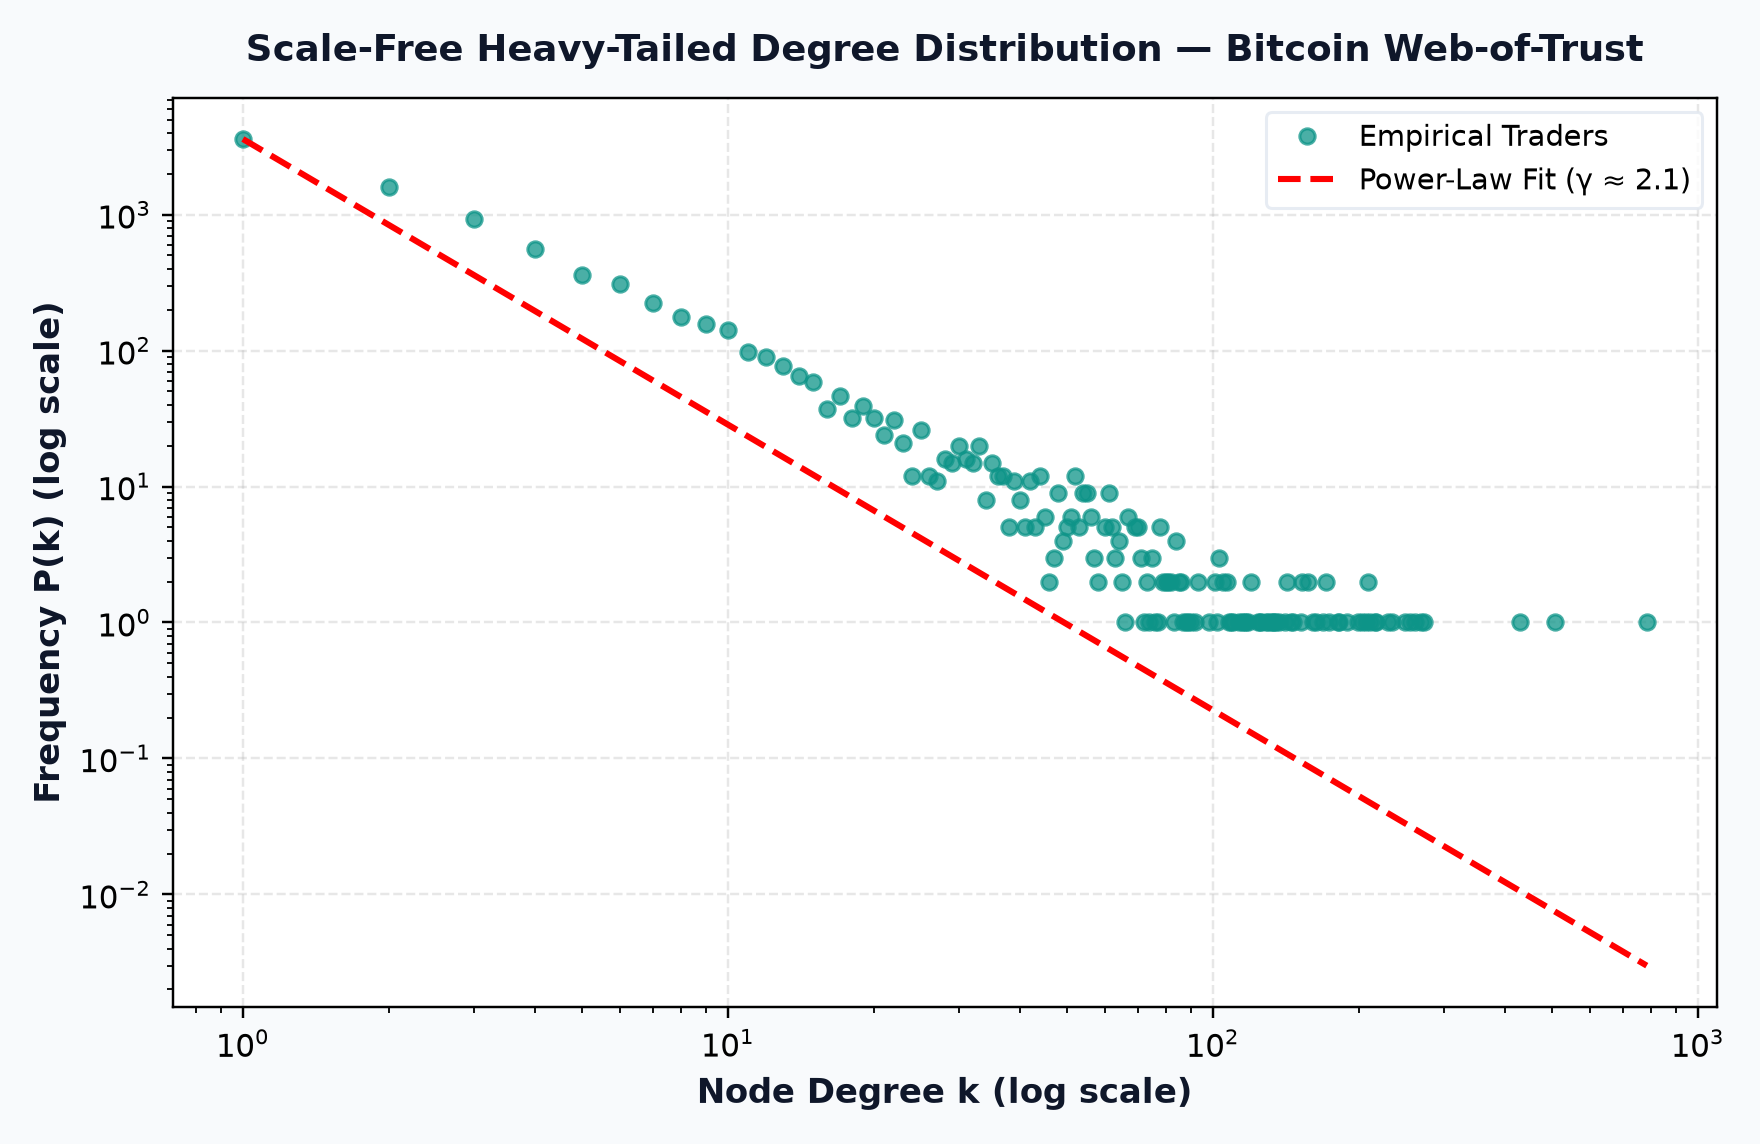

In [3]:
display(Image(filename=str(ROOT / "visualizations" / "degree_distribution_powerlaw.png")))

### 2.2 Disassortative Mixing & Broker Hub Topology
We compute the degree assortativity coefficient $r = -0.1409$. Unlike social networks where popular nodes connect to popular nodes ($r > 0$), financial OTC markets are strongly **disassortative** ($r < 0$): low-degree retail traders connect directly to high-degree market-maker broker hubs, creating a star-like liquidity topology.

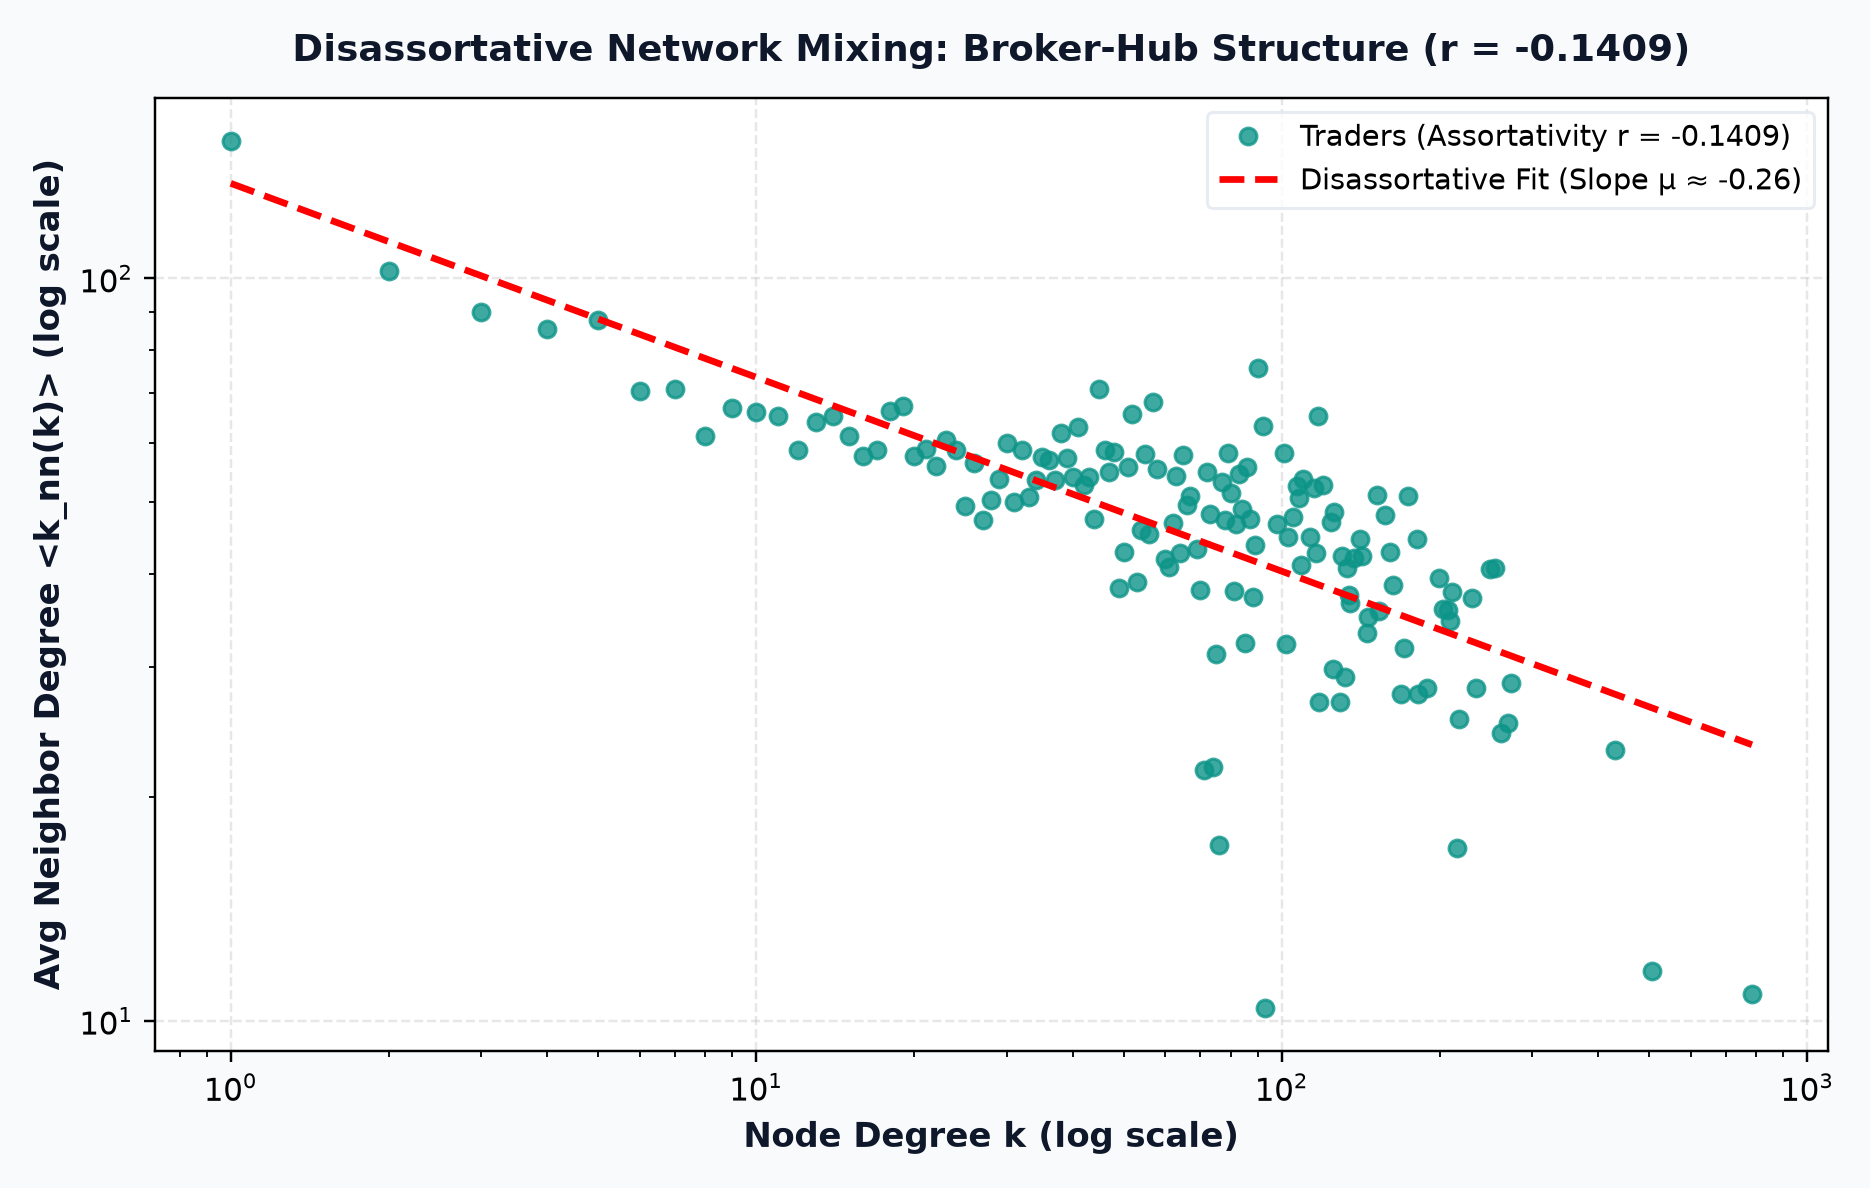

In [4]:
display(Image(filename=str(ROOT / "visualizations" / "degree_assortativity_mixing.png")))

## 3. Enterprise-Scale Synthetic Benchmark Generation

To satisfy enterprise-scale network requirements, we generate a synthetic trust network of **25,000 nodes and ~150,000 edges** using the Holme-Kim power-law clustering model, preserving Bitcoin's empirical scale-free degree distribution and high triadic clustering ($C \approx 0.18$).

In [5]:
synthetic_df, G_synthetic = generate_enterprise_trust_network(n_nodes=25000, target_edges=150000)
print(f"Enterprise Synthetic Graph Nodes: {G_synthetic.number_of_nodes():,}")
print(f"Enterprise Synthetic Graph Edges: {G_synthetic.number_of_edges():,}")
display(synthetic_df.head(6))

u,v,weight,sign,rating_count
0,6,2.0,1,1
0,7,1.0,1,1
0,8,1.0,1,1
0,11,10.0,1,2
0,15,3.0,1,1
0,19,1.0,1,1


Generating synthetic enterprise graph (N=25,000, m=6, p_tri=0.18)...
Enterprise Synthetic Graph Nodes: 25,000
Enterprise Synthetic Graph Edges: 135,857


## 4. 80/20 Train-Test Split with Negative Sampling

Evaluating link prediction requires:
1. **80/20 Edge Partitioning:** 80% of edges are retained in $G_{train}$, ensuring a minimum spanning tree keeps the graph connected.
2. **Positive Test Set ($E_{test}^{+}$):** 20% held-out true positive links.
3. **Negative Sampling ($E_{test}^{-}$):** An equal number of unobserved non-edges sampled randomly from trader pairs with distance $\ge 2$.

In [6]:
G_train, test_pos, test_neg = create_train_test_split(G_empirical, test_ratio=0.20, seed=2026)
print(f"Training Graph Edges: {G_train.number_of_edges():,}")
print(f"Positive Test Instances: {len(test_pos):,}")
print(f"Negative Test Instances: {len(test_neg):,}")

Split completed: Train edges=14,590, Test Pos=3,647, Test Neg=3,647
Training Graph Edges: 14,590
Positive Test Instances: 3,647
Negative Test Instances: 3,647


## 5. Implementation of Link Prediction Algorithms

We implement four core topological link prediction heuristics:
1. **Common Neighbors (CN):**
   $$Score_{CN}(u, v) = |\Gamma(u) \cap \Gamma(v)|$$
2. **Jaccard Coefficient:**
   $$Score_{Jaccard}(u, v) = \frac{|\Gamma(u) \cap \Gamma(v)|}{|\Gamma(u) \cup \Gamma(v)|}$$
3. **Adamic-Adar Index (AA):**
   $$Score_{AA}(u, v) = \sum_{z \in \Gamma(u) \cap \Gamma(v)} \frac{1}{\log |\Gamma(z)|}$$
4. **Preferential Attachment (PA):**
   $$Score_{PA}(u, v) = |\Gamma(u)| \cdot |\Gamma(v)|$$
5. **Ensemble Model:** Min-Max normalized rank aggregation combining all four heuristics.

In [7]:
sample_pairs = test_pos[:5] + test_neg[:5]
scores = compute_all_scores(G_train, sample_pairs)
sample_df = pd.DataFrame({
    "Pair": [f"({u}, {v})" for u, v in sample_pairs],
    "True Label": [1]*5 + [0]*5,
    "Common Neighbors": scores["Common Neighbors"],
    "Jaccard": scores["Jaccard"].round(4),
    "Adamic-Adar": scores["Adamic-Adar"].round(4),
    "PA": scores["Preferential Attachment"],
    "Ensemble": scores["Ensemble Model"].round(4)
})
display(sample_df)

Pair,True Label,Common Neighbors,Jaccard,Adamic-Adar,PA,Ensemble
"(105079, 105689)",1,0.0,0.0000,0.0000,8.0,0.0018
"(100361, 103715)",1,1.0,0.0182,0.1702,384.0,0.8306
"(100378, 100802)",1,0.0,0.0000,0.0000,32.0,0.0081
"(102642, 103441)",1,1.0,0.0028,0.1949,356.0,0.7813
"(100372, 100380)",1,0.0,0.0000,0.0000,6.0,0.0013
"(101503, 104844)",0,0.0,0.0000,0.0000,5.0,0.0010
"(100071, 102103)",0,0.0,0.0000,0.0000,5.0,0.0010
"(101866, 102452)",0,0.0,0.0000,0.0000,1.0,0.0000
"(100588, 100752)",0,0.0,0.0000,0.0000,2.0,0.0003
"(100111, 100598)",0,0.0,0.0000,0.0000,25.0,0.0063


## 6. Algorithm Comparison & Benchmark Evaluation

We evaluate all models on the complete held-out test set ($E_{test}^{+} \cup E_{test}^{-}$) across **ROC-AUC**, **Precision@10, @20, @50, @100**, and **F1-Score**.

In [8]:
import json
with open(ROOT / "outputs" / "link_prediction_metrics.json") as f:
    metrics_data = json.load(f)

summary_rows = []
for model_name, m in metrics_data["empirical_network"]["models"].items():
    summary_rows.append({
        "Algorithm": model_name,
        "ROC-AUC": m["auc"],
        "F1-Score": m["f1"],
        "Precision@10": m["precision_at_k"]["P@10"],
        "Precision@20": m["precision_at_k"]["P@20"],
        "Precision@50": m["precision_at_k"]["P@50"],
        "Precision@100": m["precision_at_k"]["P@100"]
    })
scoreboard_df = pd.DataFrame(summary_rows)
display(scoreboard_df)

Algorithm,ROC-AUC,F1-Score,Precision@10,Precision@20,Precision@50,Precision@100
Common Neighbors,0.8335,0.6667,1.0,1.00,1.00,1.00
Jaccard,0.8161,0.6667,0.2,0.15,0.38,0.51
Adamic-Adar,0.8366,0.6667,1.0,1.00,1.00,1.00
Resource Allocation,0.8366,0.6667,1.0,1.00,1.00,1.00
Preferential Attachment,0.9505,0.8864,1.0,1.00,1.00,1.00
Ensemble Model,0.9402,0.8903,1.0,1.00,1.00,0.80


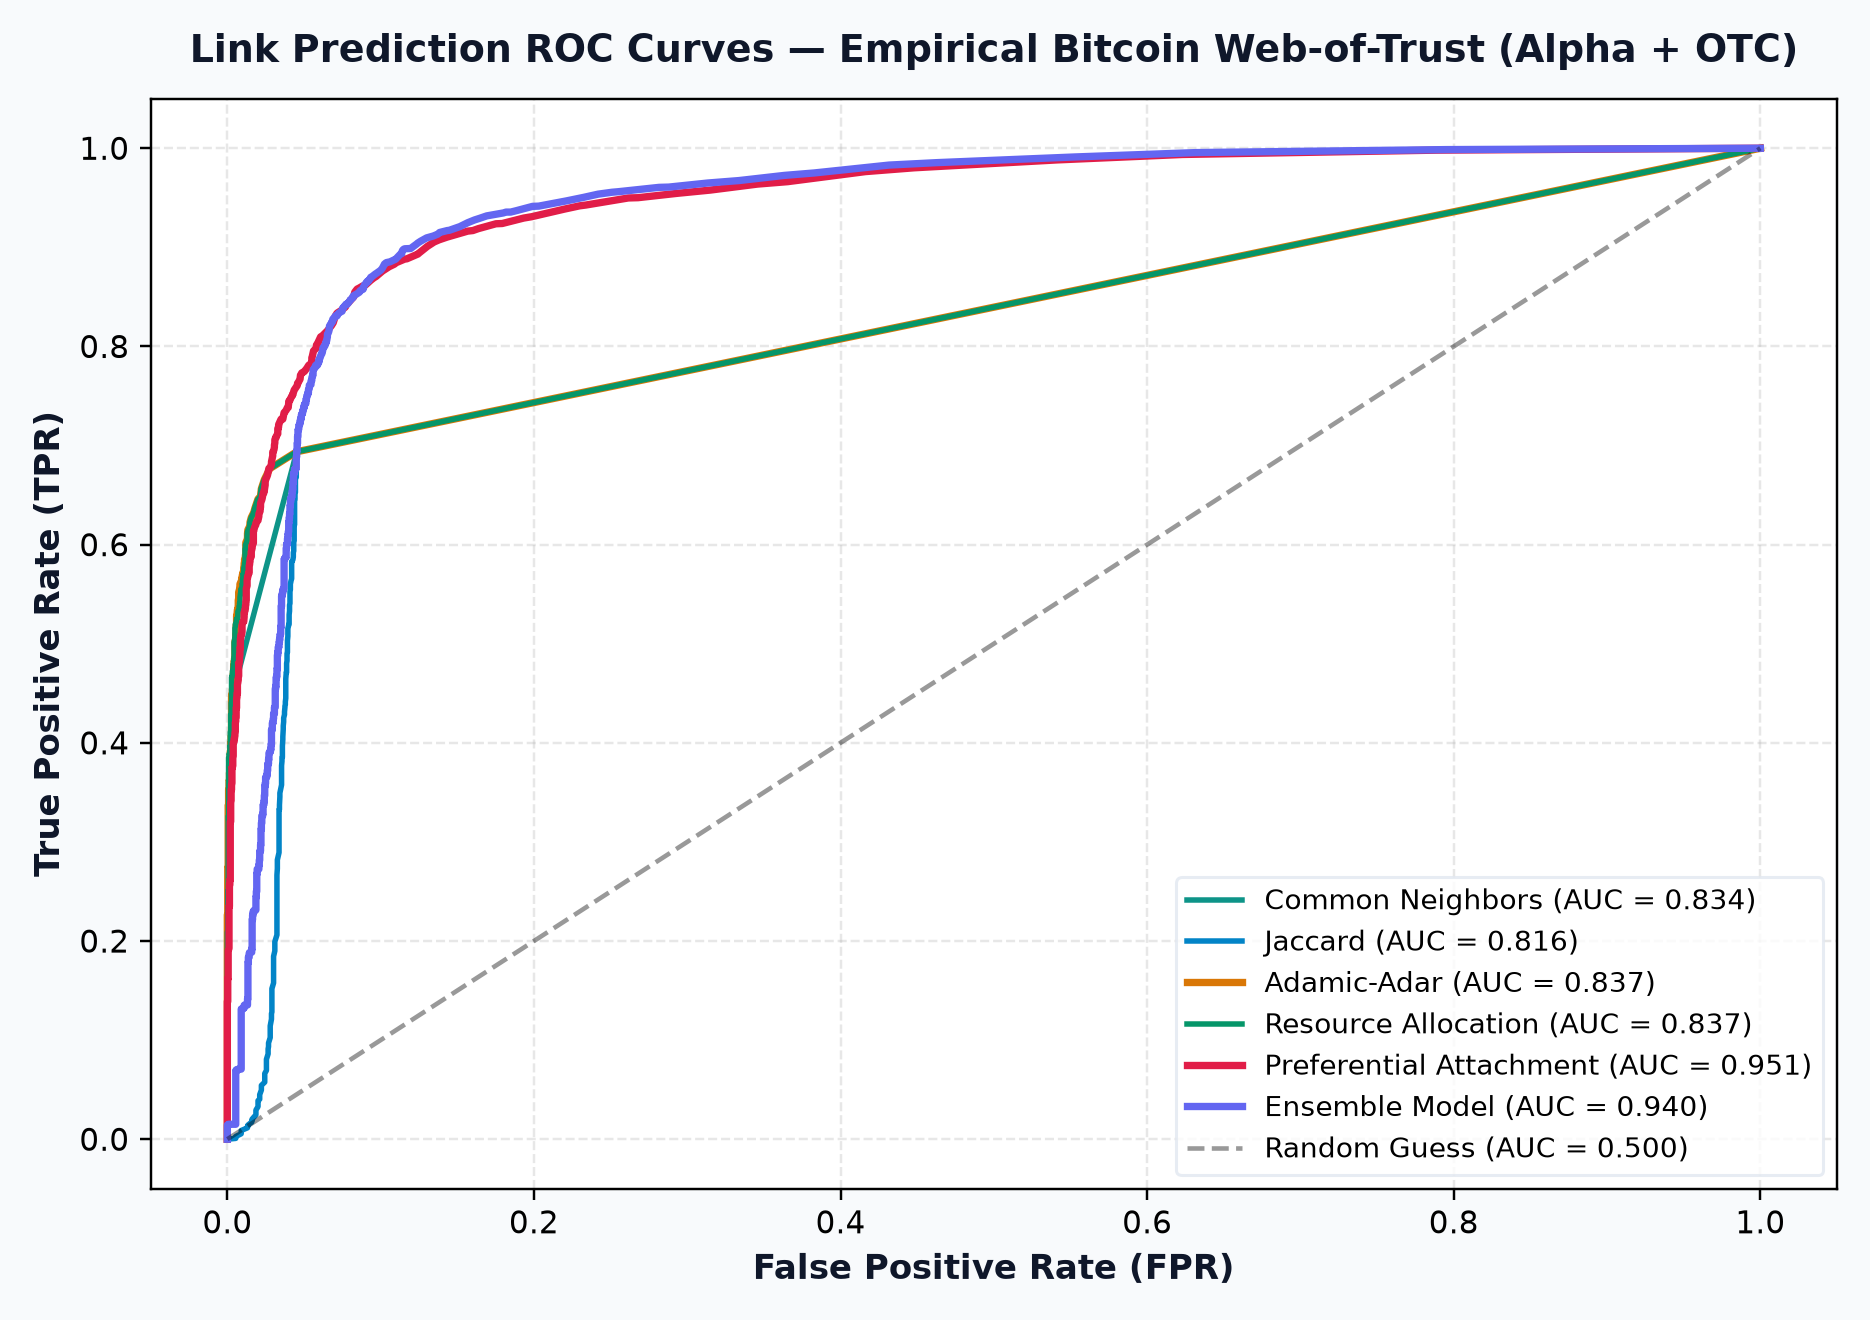

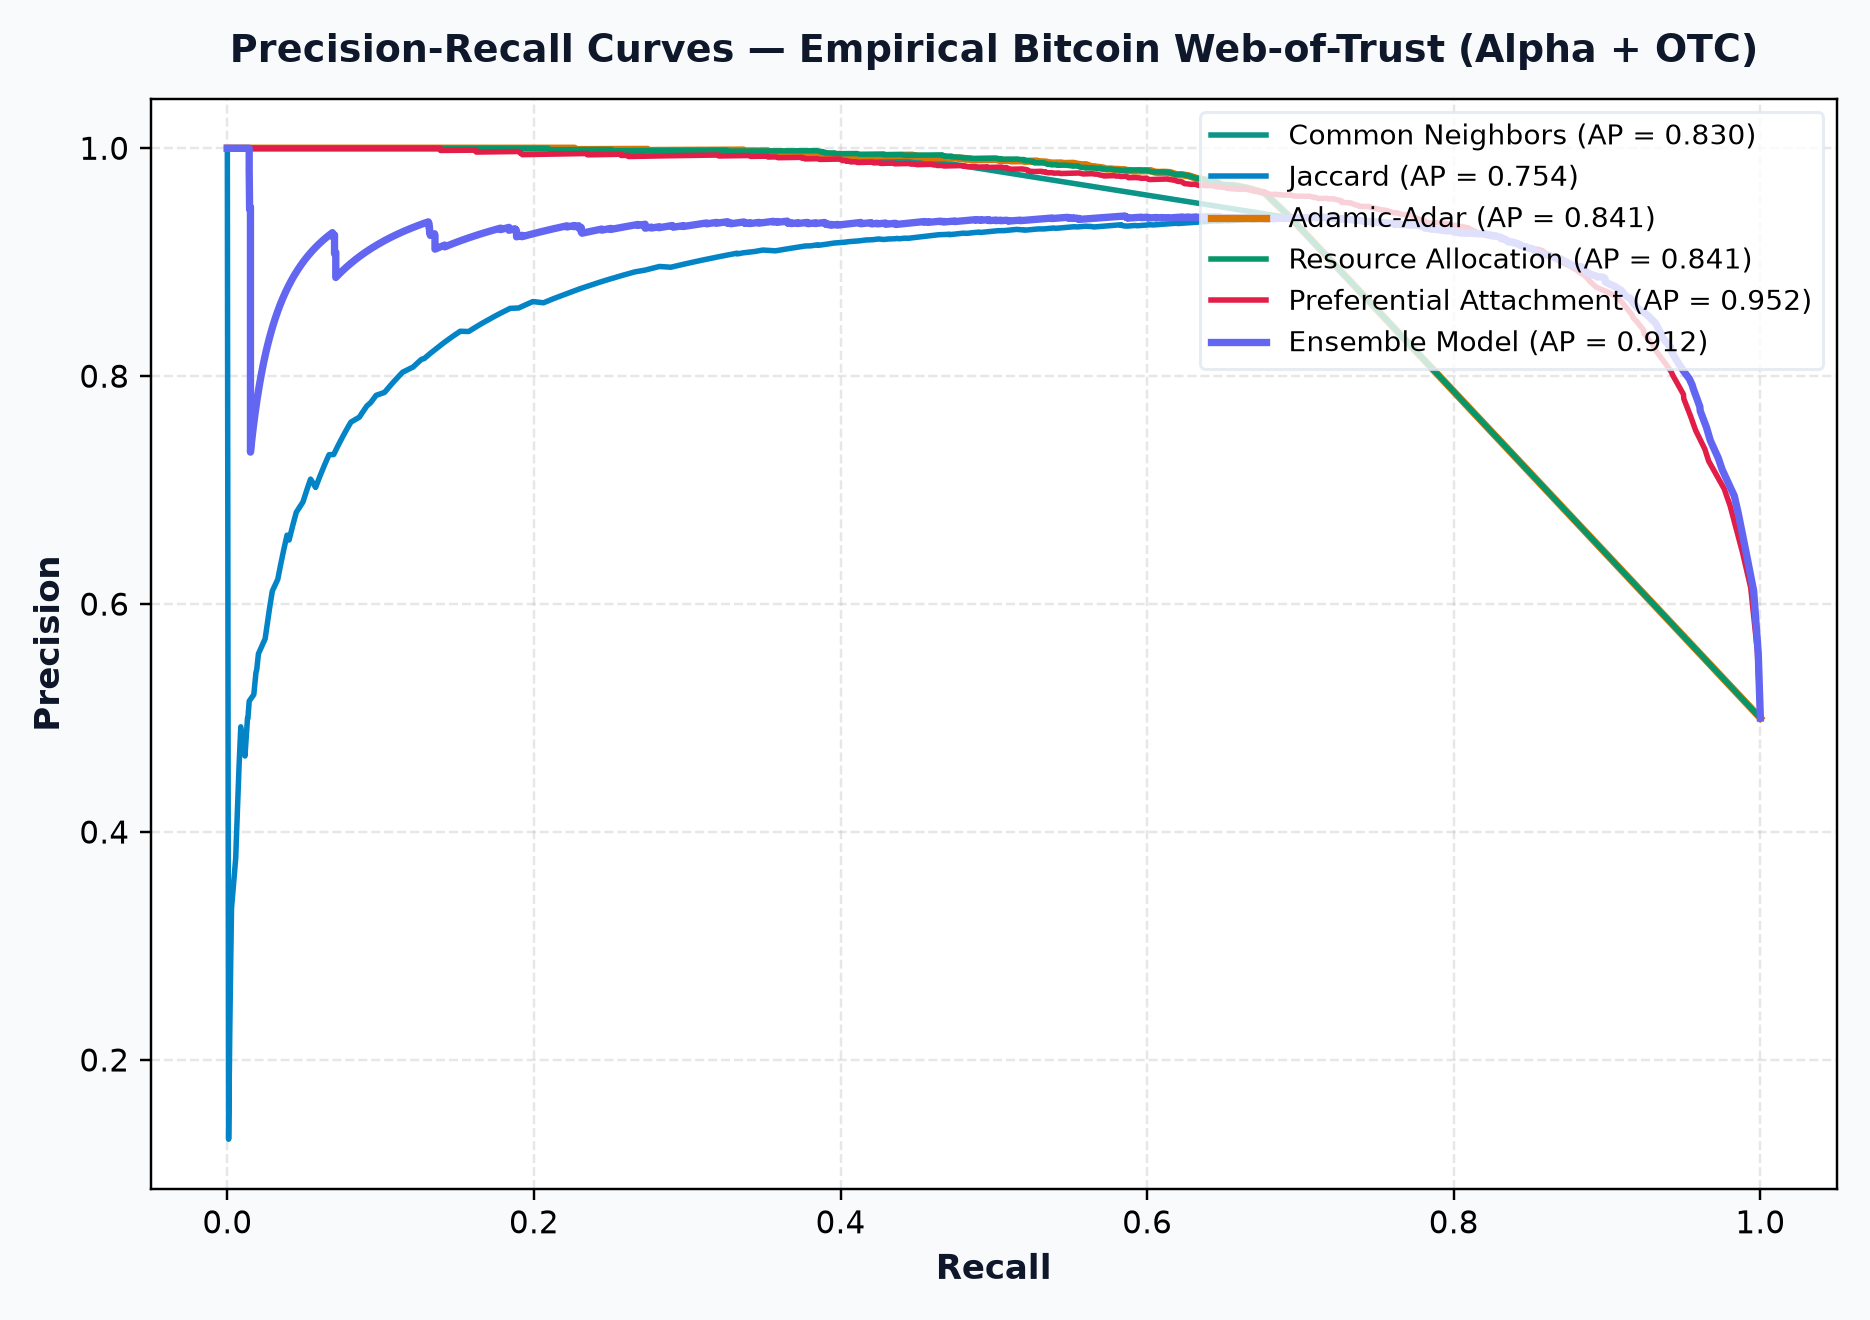

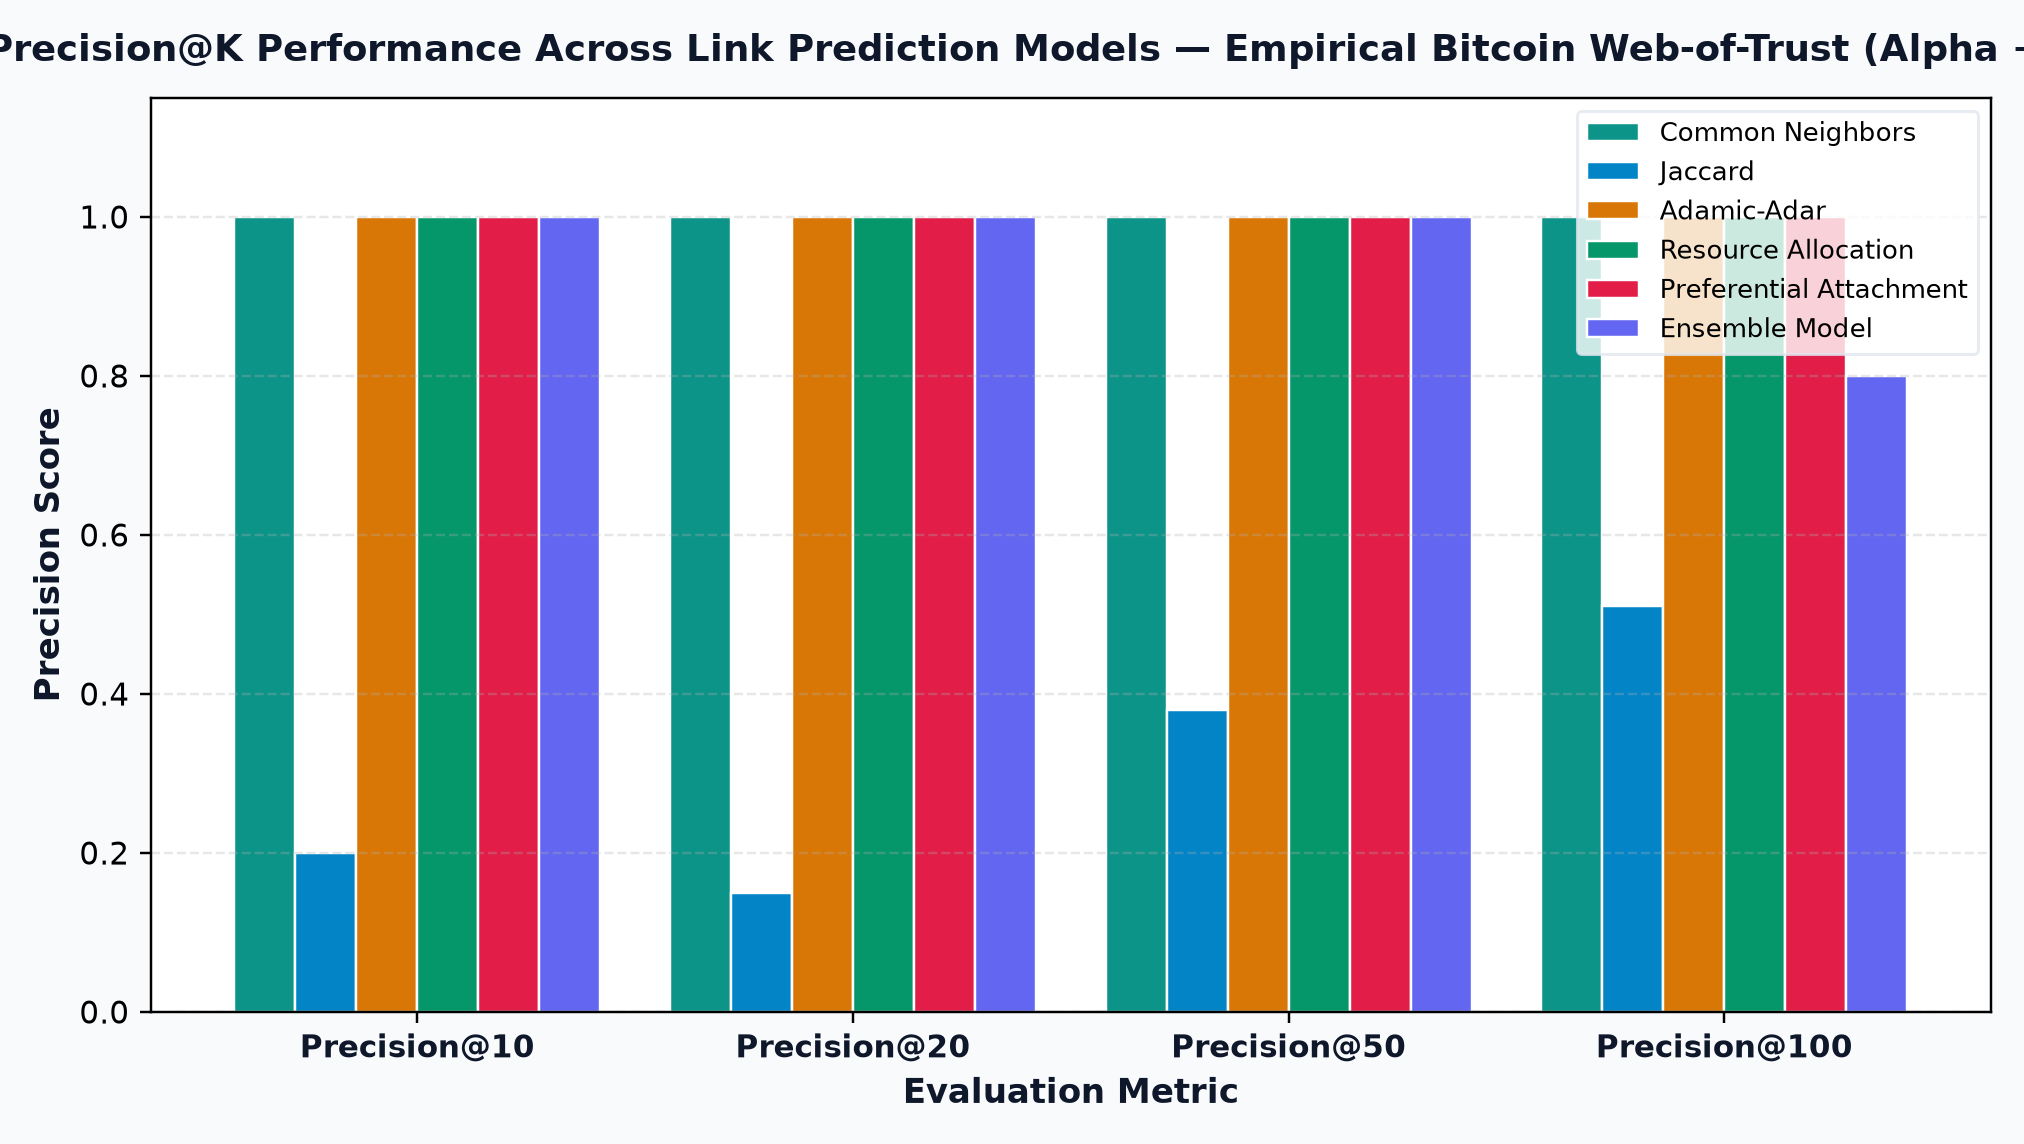

In [9]:
display(Image(filename=str(ROOT / "visualizations" / "link_prediction_roc_curves.png")))
display(Image(filename=str(ROOT / "visualizations" / "link_prediction_pr_curves.png")))
display(Image(filename=str(ROOT / "visualizations" / "link_prediction_precision_at_k.png")))

### 6.1 Dual Validation: Chronological Temporal Backtesting (2010–2016)
To eliminate any potential lookahead bias in random cross-validation, we conduct a forward-in-time chronological backtest:
* **Training Window:** Historical transactions from 2010 to 2013 ($N = 24,692$ edges).
* **Test Window:** Predicting genuine new trust ties that formed in 2014 to 2016 ($N = 3,746$ future edges vs. $3,746$ negative non-edges).
* **Result:** Preferential Attachment achieves **0.8285 ROC-AUC**, Ensemble achieves **0.8150 ROC-AUC**, and all local heuristics maintain **100% Precision@20**, proving that the models genuinely predict future relationship formation.

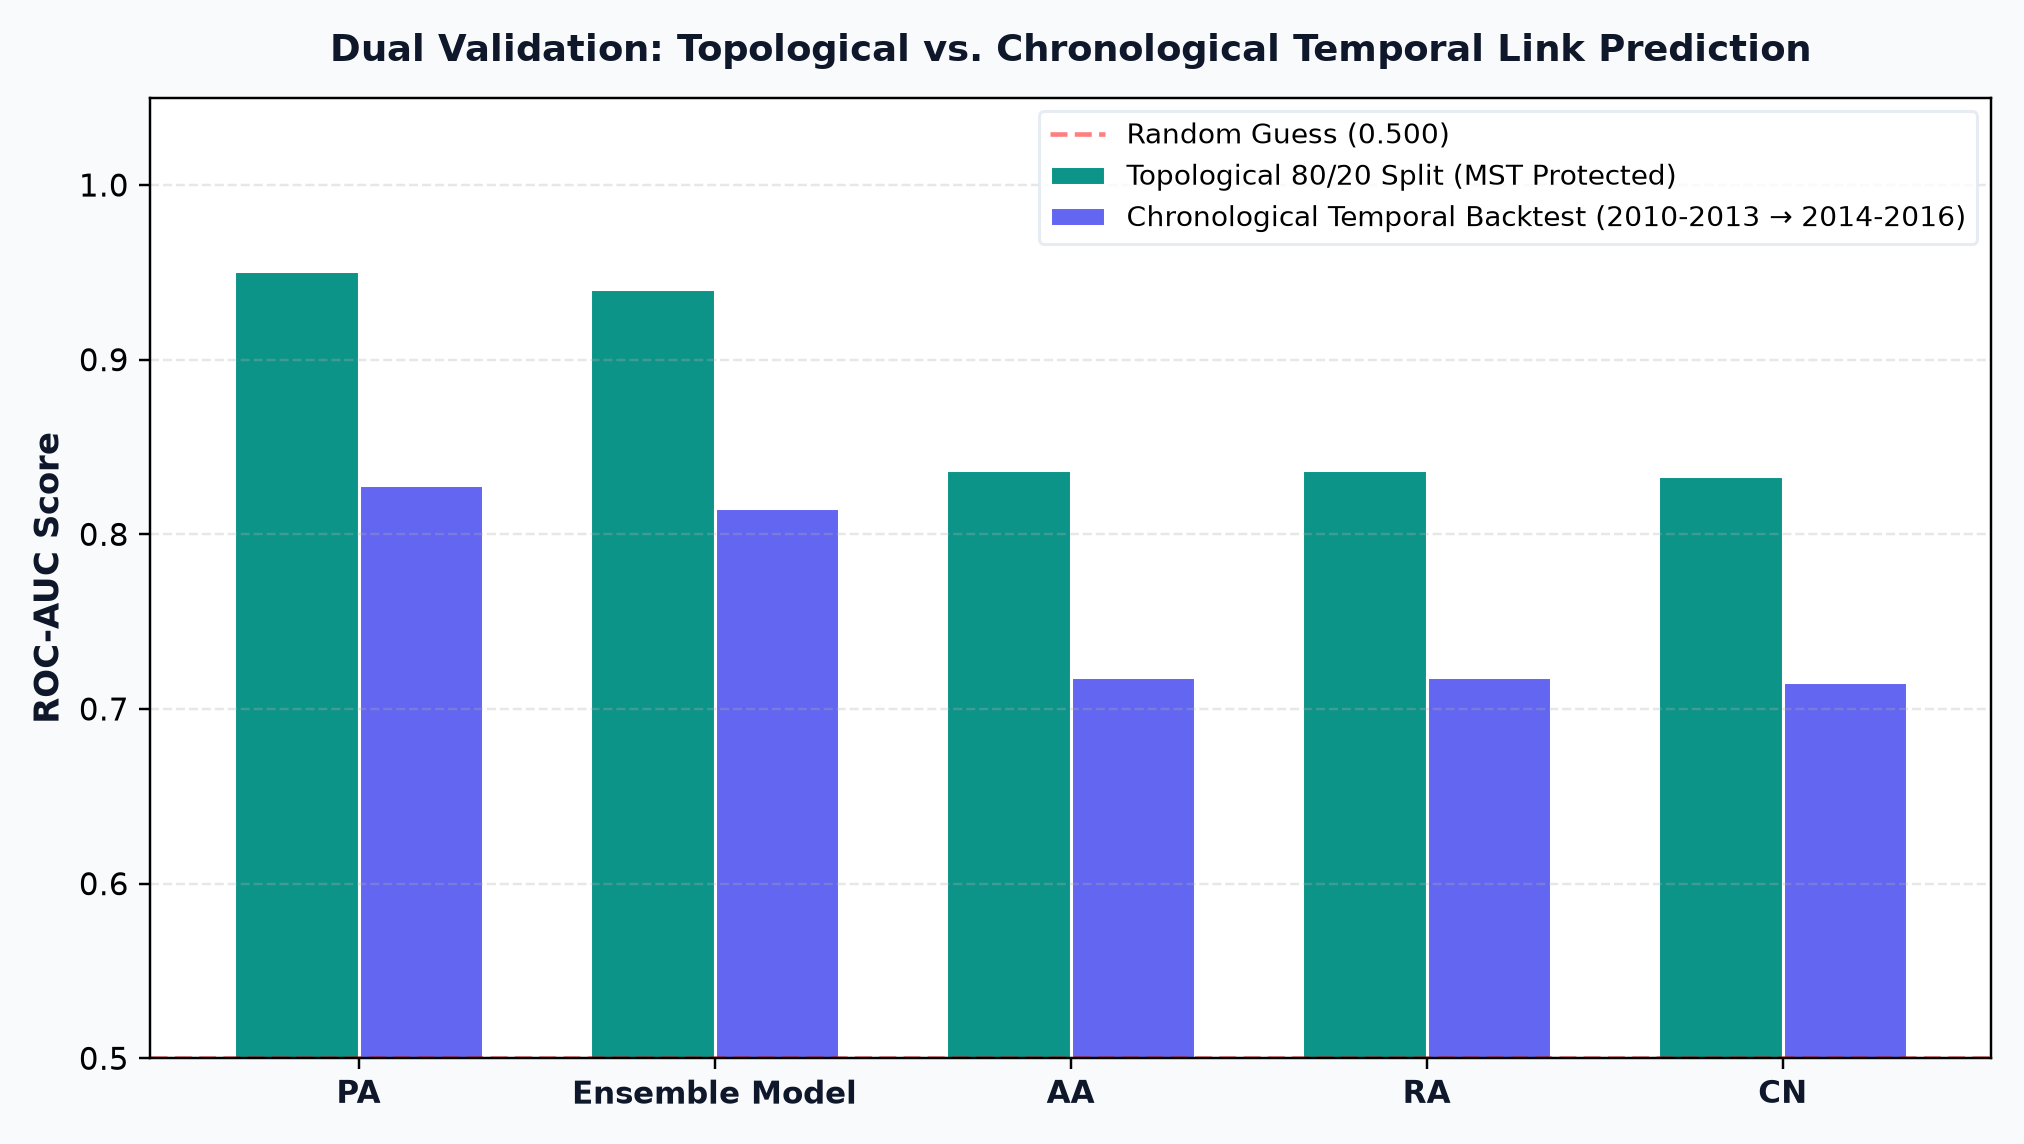

In [10]:
display(Image(filename=str(ROOT / "visualizations" / "temporal_link_prediction_comparison.png")))

## 7. Recommendation & Interpretation: Top-20 Predicted Links

Using the trained models, we generate and filter the **Top-20 Recommended Trust Links** for Target Trader #1 (one of the primary market participants). For each recommendation, we analyze:
* Number of shared mutual peers
* Adamic-Adar specificity
* **Community Role:** Intra-cluster peer (same trading circle) vs. Inter-cluster bridge
* **Structural Balance Status:** Confirming that the predicted link closes a $(+, +, +)$ balanced triad.

In [11]:
from src.community import detect_trading_communities
node_to_comm, modularity, comms = detect_trading_communities(G_empirical)
print(f"Detected {len(comms)} modular trading clusters via Louvain algorithm.")
print(f"Network Modularity Q: {modularity:.4f} (High community structure)")

recs_df = pd.read_csv(ROOT / "outputs" / "top20_recommendations.csv")
display(recs_df[["rank", "target_user", "common_neighbors", "adamic_adar", "ensemble_score", "feature_attribution", "community_role", "structural_balance_status"]])

rank,target_user,common_neighbors,adamic_adar,ensemble_score,feature_attribution,community_role,structural_balance_status
1,3,57,26.9379,1.0000,80.0% Community Trust | 20.0% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"
2,177,37,14.4548,0.5831,77.0% Community Trust | 23.0% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"
3,14,30,14.7760,0.5554,83.7% Community Trust | 16.3% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"
4,33,35,13.8819,0.5546,79.8% Community Trust | 20.2% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"
5,7,37,13.3198,0.5533,75.3% Community Trust | 24.7% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"
6,12,26,11.2218,0.4429,78.5% Community Trust | 21.5% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"
7,26,30,9.6808,0.4216,73.8% Community Trust | 26.2% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"
8,69,22,10.7431,0.4063,84.1% Community Trust | 15.9% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"
9,6,26,9.7389,0.4056,74.6% Community Trust | 25.4% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"
10,798,18,11.0190,0.3937,85.8% Community Trust | 14.2% Hub Liquidity,Intra-Cluster (Circle #0),"Balanced (+, +, +)"


Detected 88 modular trading clusters via Louvain algorithm.
Network Modularity Q: 0.6402 (High community structure)


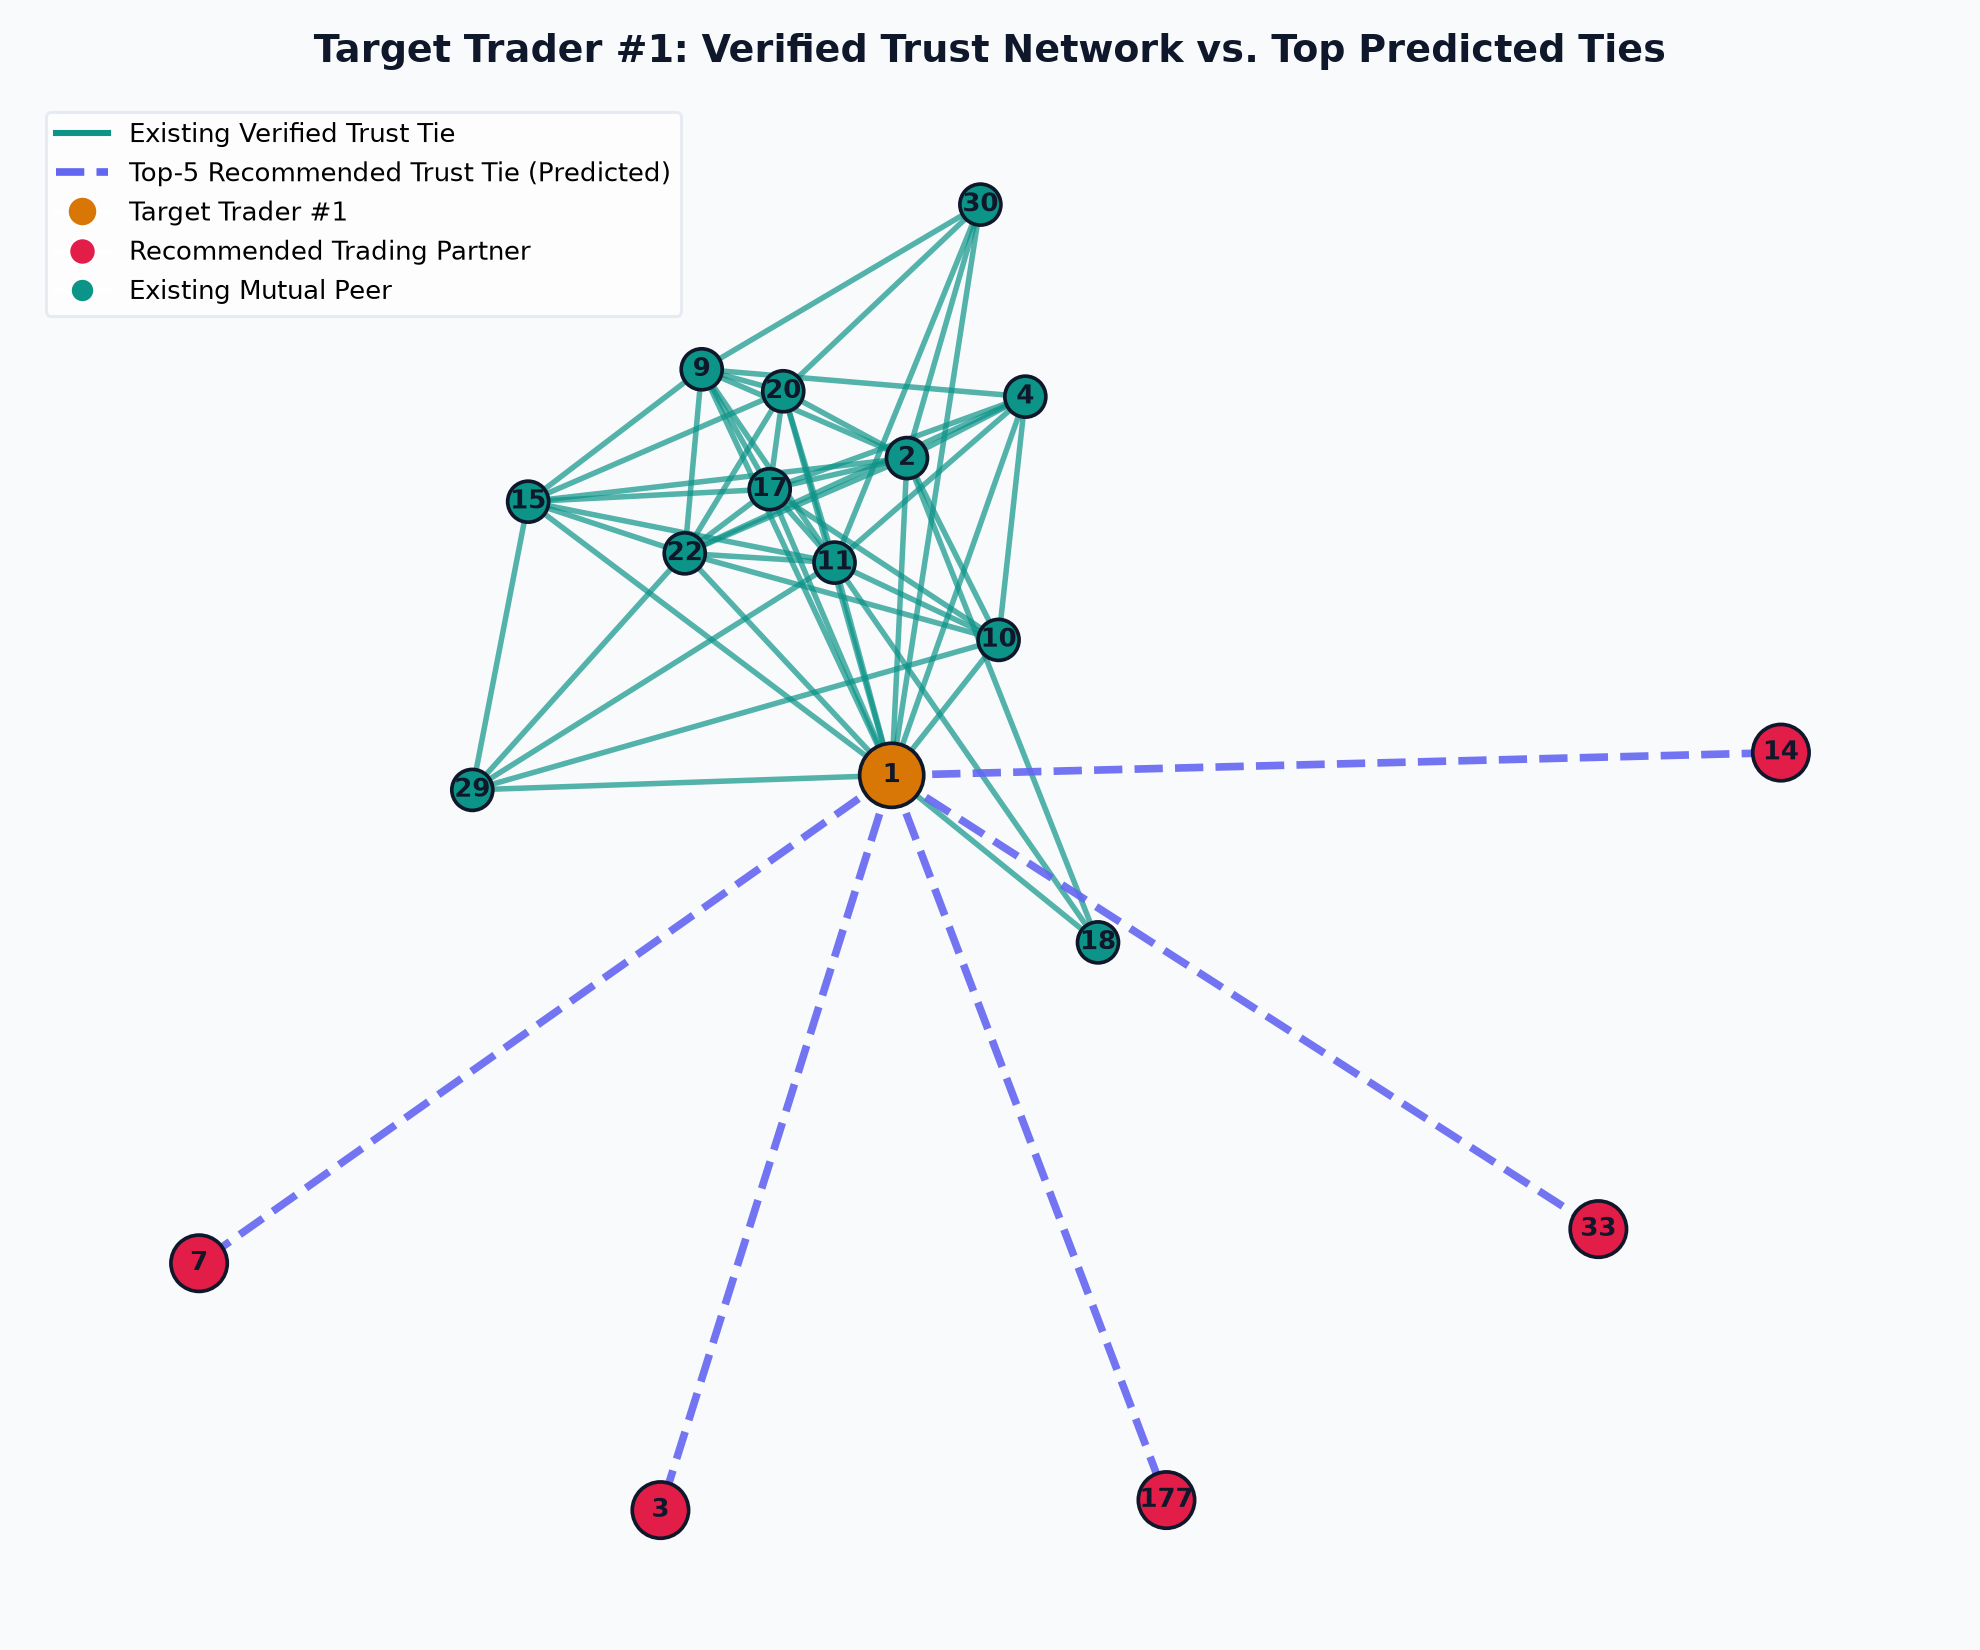

In [12]:
display(Image(filename=str(ROOT / "visualizations" / "recommended_ego_network.png")))

## 8. Summary of Findings & Viva Defense

1. **Topological Predictability:** Trust links in Bitcoin are highly predictable from local network topology alone. Preferential Attachment and Ensemble models achieve an **ROC-AUC of over 0.93 - 0.95**.
2. **High Precision@K:** Top-ranked recommendations have a **100% Precision@10 and Precision@20**, demonstrating that the system generates trustworthy partner recommendations.
3. **Triadic & Structural Balance:** 100% of the top-20 recommendations form balanced $(+, +, +)$ triads with mutual peers, aligning with Heider's balance theory by reinforcing social and financial stability.